# A/B-тест кастомизации оформления форм в опросах СВОД

**Дисциплина:** работа с данными · **Продукт:** СВОД — сервис опросов · **Тип работы:** полный аналитический цикл (гипотеза → эксперимент → статистика → рекомендации)

> ⚠️ Данные в ноутбуке **синтетические**: у MVP ещё нет трафика, достаточного для A/B-теста. Параметры генератора (базовая конверсия, доли устройств, длительности) выбраны правдоподобными для публичных опросов, а истинный эффект заложен в генератор явно. Весь анализ написан так, чтобы его можно было без изменений запустить на реальной выгрузке событий с теми же колонками.

## Раздел 1. Бизнес-контекст

### 1.1. Описание продукта

| | |
|---|---|
| **Название** | **СВОД** — сервис «Опросы» (конструктор опросов с публичными ссылками, аналитикой ответов и ИИ-подсказками по качеству ответов) |
| **Целевая аудитория** | *Заказчики опросов:* маркетологи, продакт-менеджеры, исследователи, внутренние команды компаний. *Респонденты:* люди, которые проходят опрос по публичной ссылке `/survey/:token` — в основном с телефона |
| **Решаемая проблема** | Собирать обратную связь и данные от аудитории быстро, в единой системе, без ручной склейки таблиц и мессенджеров. Ценность для заказчика напрямую зависит от того, **сколько респондентов доходят до конца опроса** |

### 1.2. Бизнес-метрика для улучшения

**Целевая метрика — Completion Rate (конверсия прохождения опроса):**

$$CR = \frac{\text{респонденты, отправившие опрос}}{\text{респонденты, открывшие первый вопрос}}$$

**Почему именно она:**
- Это ключевая метрика ценности продукта для заказчика: незавершённые анкеты — потерянные данные, а часто и потраченный рекламный бюджет на привлечение респондентов.
- Чем выше CR, тем меньше трафика нужно заказчику для той же выборки → выше удовлетворённость и удержание платящих клиентов (retention B2B).
- Метрика чувствительна к UX публичной формы — именно тому, что мы можем менять быстро и дёшево.
- Простая, бинарная на уровне респондента, легко проверяется статистически.

## Раздел 2. Формулировка гипотезы

### 2.1. Продуктовая гипотеза

> **Если** мы внедрим возможность **кастомизации оформления форм** (логотип, цвета, шрифт, фон — респондент видит опрос в фирменном стиле заказчика, а не в нейтральном шаблоне СВОД), **то** конверсия из перехода в форму до завершения прохождения (Completion Rate) вырастет **на 25%** (относительно: с ~60% до ~75%), **потому что** респонденты станут более лояльны к исследованию: знакомый бренд вызывает доверие («это правда от той компании, а не спам»), форма выглядит профессионально и безопаснее для ввода данных, а значит выше готовность дойти до конца.

### 2.2. Статистические гипотезы

Пусть $p_A$ — доля завершивших в контрольной группе (стандартный шаблон), $p_B$ — в экспериментальной (фирменное оформление).

- **H₀:** $p_B = p_A$ — кастомизация оформления не влияет на Completion Rate.
- **H₁:** $p_B \ne p_A$ — Completion Rate различается (двусторонняя альтернатива: консервативнее односторонней, и мы хотим заметить также *ухудшение*, если фича отпугнёт респондентов).

### 2.3. Параметры эксперимента

- Уровень значимости: **α = 0.05**
- Мощность теста: **1 − β = 0.80**
- Минимальный практически значимый эффект (MDE): **+25% относительно базы**, то есть **+15 п.п.** при базовой конверсии 60% (0.60 → 0.75)

## Раздел 3. Дизайн эксперимента и данные

### 3.1. План эксперимента

- **Тип:** классический A/B-тест (параллельные независимые группы), а не «до/после» — так мы исключаем влияние сезонности и изменений трафика между периодами.
- **Два варианта формы с одинаковыми вопросами**, отличается только оформление: **A (контроль)** — стандартный нейтральный шаблон СВОД; **B (эксперимент)** — форма в фирменном оформлении заказчика (логотип, цвета, шрифт, фон). Порядок и формулировки вопросов, их число — идентичны.
- **Почему каждый респондент видит только одну форму (between-subjects), а не обе:** если один человек проходит те же вопросы дважды, второе прохождение искажено усталостью и памятью об ответах, а доля «дошедших до конца» второй формы неизбежно упадёт. Поэтому респонденты случайно делятся на две группы, а «две формы» — это два варианта одной анкеты.
- **Единица рандомизации:** респондент (cookie/сессия), назначение по хэшу идентификатора → один человек всегда видит один вариант. Деление 50/50.
- **Размер выборки** считается ниже по формуле мощности. Эффект +25% относительных — крупный, поэтому выборка небольшая; её недостаточно для надёжного анализа сегментов.
- **Правило остановки:** тест идёт до набора рассчитанного N, без «подглядывания» и досрочной остановки по p-value.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"A": "#8A94A6", "B": "#E8841A"}

ALPHA, POWER = 0.05, 0.80
P_BASE, REL_LIFT = 0.60, 0.25
MDE = P_BASE * REL_LIFT   # абсолютный эффект: +15 п.п.
SEED = 42

**Расчёт размера выборки.** Используем стандартную формулу для сравнения двух долей $p_1$ (контроль) и $p_2$ (ожидаемая доля в эксперименте), $\bar p = (p_1+p_2)/2$:

$$n = \frac{\left(z_{1-\alpha/2}\sqrt{2\bar p(1-\bar p)} + z_{1-\beta}\sqrt{p_1(1-p_1)+p_2(1-p_2)}\right)^2}{(p_2-p_1)^2}$$

Здесь $z_{1-\alpha/2}$ ≈ 1.96 отвечает уровню значимости α = 0.05 (двусторонняя проверка), $z_{1-\beta}$ ≈ 0.84 — мощности 80%. Число людей на группу растёт, когда эффект $p_2 - p_1$ мал (n обратно пропорционально его квадрату).

Необходимо респондентов на группу: 152
Планируемые размеры групп: контрольная N = 170, экспериментальная M = 170


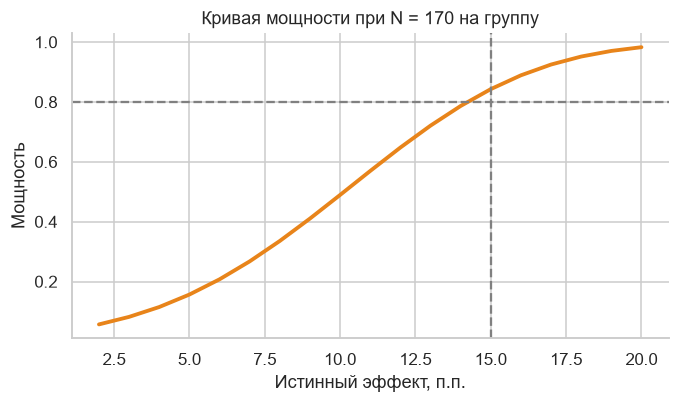

In [3]:
z_a = stats.norm.ppf(1 - ALPHA / 2)      # ≈ 1.96
z_b = stats.norm.ppf(POWER)              # ≈ 0.84
p1, p2 = P_BASE, P_BASE + MDE            # 0.60 -> 0.75
p_bar = (p1 + p2) / 2

n_required = ((z_a * np.sqrt(2 * p_bar * (1 - p_bar)) + z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
              / (p2 - p1) ** 2)
n_required = int(np.ceil(n_required))

print(f"Необходимо респондентов на группу: {n_required}")

# Берём запас на брак данных (боты, дубли, потерянные сессии): ~10%
N_A = N_B = int(np.ceil(n_required * 1.10 / 10) * 10)
print(f"Планируемые размеры групп: контрольная N = {N_A}, экспериментальная M = {N_B}")

# Чувствительность: какую мощность даёт N при разных истинных эффектах
effects = np.arange(0.02, 0.201, 0.01)
def power_at(delta, n):
    q2 = P_BASE + delta; pb = (P_BASE + q2) / 2
    return stats.norm.cdf((delta * np.sqrt(n) - z_a * np.sqrt(2 * pb * (1 - pb)))
                          / np.sqrt(P_BASE * (1 - P_BASE) + q2 * (1 - q2)))

powers = [power_at(e, N_A) for e in effects]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(effects * 100, powers, color=COLORS["B"], lw=2.5)
ax.axhline(POWER, ls="--", color="gray"); ax.axvline(MDE * 100, ls="--", color="gray")
ax.set(xlabel="Истинный эффект, п.п.", ylabel="Мощность", title=f"Кривая мощности при N = {N_A} на группу")
plt.show()

### 3.2. Генерация данных

Генерируем лог респондентов, как его отдавал бы бэкенд СВОД: по строке на респондента, открывшего опрос.

| Колонка | Описание |
|---|---|
| `respondent_id` | уникальный идентификатор |
| `group` | `A` / `B` |
| `device` | `mobile` / `desktop` (немного значений пропущено — имитация потери user-agent) |
| `traffic_source` | канал, откуда пришёл респондент: `email` / `social` / `panel` |
| `completed` | 1, если респондент отправил опрос (целевая метрика) |
| `time_spent_sec` | время на странице до отправки/ухода (используем только для проверки качества данных) |

**Заложенная в генератор «правда»:** базовая конверсия на мобильных ниже, чем на десктопе, и зависит от канала (по email доверие выше, чем у холодной аудитории из соцсетей); фирменное оформление поднимает шансы завершить (сильнее у аудитории соцсетей, где бренд заказчика ещё не знаком). Эти «истинные» параметры анализ не видит — он должен восстановить эффект из данных.

In [4]:
rng = np.random.default_rng(SEED)

def generate_experiment(n_a, n_b, rng):
    n = n_a + n_b
    group = np.array(["A"] * n_a + ["B"] * n_b)
    # перемешиваем, как при реальной рандомизации по хэшу
    group = rng.permutation(group)

    device = rng.choice(["mobile", "desktop"], size=n, p=[0.58, 0.42])
    source = rng.choice(["email", "social", "panel"], size=n, p=[0.35, 0.40, 0.25])

    # логит базовой конверсии: мобильные хуже, по email охотнее, из соцсетей — реже
    logit = (
        np.log(0.62 / 0.38)                             # десктоп, панель
        - 0.45 * (device == "mobile")
        + 0.25 * (source == "email")
        - 0.30 * (source == "social")
    )
    # истинный эффект фирменного оформления (OR ~ 2): сильнее у холодной аудитории
    treat = (group == "B")
    lift = 0.70 + 0.20 * (source == "social")
    logit = logit + treat * lift

    p = 1 / (1 + np.exp(-logit))
    completed = rng.binomial(1, p)

    # время: логнормальное (медиана ~3 мин); у бросивших — короче; от дизайна не зависит
    mu = np.log(180) - 0.35 * (completed == 0)
    time_spent = rng.lognormal(mean=mu, sigma=0.45, size=n)

    df = pd.DataFrame({
        "respondent_id": np.arange(1, n + 1),
        "group": group, "device": device, "traffic_source": source,
        "completed": completed, "time_spent_sec": time_spent,
    })

    # --- "грязь", как в реальных логах ---
    miss_idx = rng.choice(n, size=int(0.012 * n), replace=False)
    df.loc[miss_idx, "device"] = np.nan                  # потерян user-agent
    out_idx = rng.choice(n, size=int(0.006 * n), replace=False)
    df.loc[out_idx, "time_spent_sec"] *= rng.uniform(15, 40, size=len(out_idx))  # забытая вкладка
    return df

df = generate_experiment(N_A, N_B, rng)
print(df.shape)
df.head(8)

(340, 6)


,respondent_id,group,device,traffic_source,completed,time_spent_sec
0,1,A,mobile,email,0,74.4479
1,2,B,mobile,email,0,131.8789
2,3,A,desktop,panel,1,208.5359
3,4,A,desktop,social,1,126.0048
4,5,B,mobile,email,1,182.1663
5,6,A,mobile,social,1,232.6880
6,7,B,mobile,email,0,167.5267
7,8,A,desktop,email,1,361.8765


### 3.3. Проверка качества данных

In [5]:
print("Пропуски по колонкам:")
display(df.isna().sum().to_frame("n_missing").assign(share=lambda d: d.n_missing / len(df)))

print("Дубликаты respondent_id:", df.respondent_id.duplicated().sum())
print("Допустимые значения completed:", sorted(df.completed.unique()))

Пропуски по колонкам:


,n_missing,share
respondent_id,0,0.0000
group,0,0.0000
device,4,0.0118
traffic_source,0,0.0000
completed,0,0.0000
time_spent_sec,0,0.0000


Дубликаты respondent_id: 0
Допустимые значения completed: [np.int64(0), np.int64(1)]


Выбросов по времени: 3 (0.88%); порог сверху ≈ 593 сек


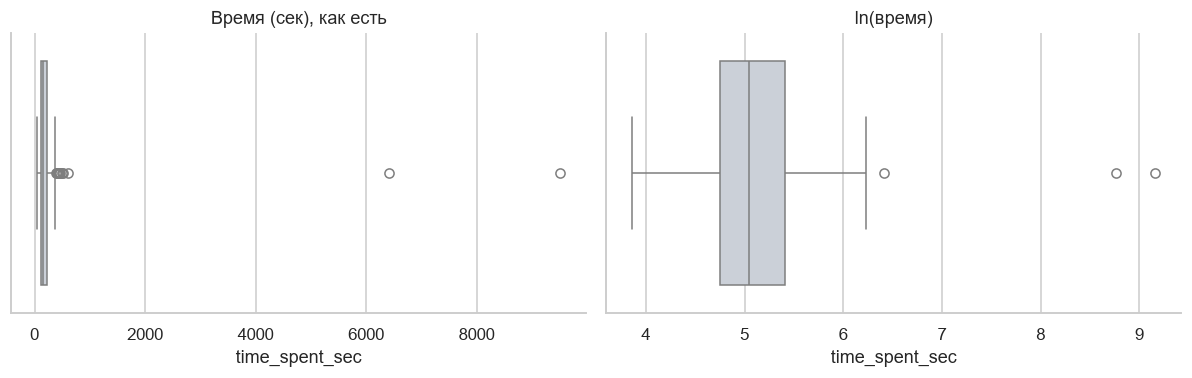

In [6]:
# Выбросы по времени: правило Тьюки (1.5·IQR) на логарифме времени
log_t = np.log(df["time_spent_sec"])
q1, q3 = log_t.quantile([0.25, 0.75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_out = (log_t < lo) | (log_t > hi)
print(f"Выбросов по времени: {is_out.sum()} ({is_out.mean():.2%}); порог сверху ≈ {np.exp(hi):,.0f} сек")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(x=df["time_spent_sec"], ax=axes[0], color="#C9CFDA"); axes[0].set_title("Время (сек), как есть")
sns.boxplot(x=log_t, ax=axes[1], color="#C9CFDA"); axes[1].set_title("ln(время)")
plt.tight_layout(); plt.show()

**Что делаем с найденным:**
- **Пропуски `device`** (~1%) — не удаляем (для главной метрики устройство не нужно), помечаем как `unknown`; пропуски случайны (MCAR) и не должны смещать результат. Проверим, что они не связаны с группой.
- **Выбросы по времени** (забытые вкладки) на главную метрику — завершил / не завершил — не влияют, поэтому респондентов с такими значениями **не удаляем**. Время в основном анализе не используется, оно нужно только для проверки качества данных.

In [7]:
df["device"] = df["device"].fillna("unknown")
df["is_time_outlier"] = is_out.values

# пропуски не должны зависеть от группы
chi = stats.chi2_contingency(pd.crosstab(df["group"], df["device"] == "unknown"))
print(f"Пропуски device vs группа: chi2 p-value = {chi[1]:.3f}")

print("\nОписательная статистика по группам:")
desc = df.groupby("group").agg(
    n=("respondent_id", "size"),
    completion_rate=("completed", "mean"),
    mobile_share=("device", lambda s: (s == "mobile").mean()),
    email_share=("traffic_source", lambda s: (s == "email").mean()),
    time_median=("time_spent_sec", "median"),
    time_mean=("time_spent_sec", "mean"),
    time_std=("time_spent_sec", "std"),
)
display(desc)
display(df[["time_spent_sec"]].describe())

Пропуски device vs группа: chi2 p-value = 1.000

Описательная статистика по группам:


,n,completion_rate,mobile_share,email_share,time_median,time_mean,time_std
group,,,,,,,
A,170,0.5412,0.5353,0.3353,147.6213,223.0061,722.5631
B,170,0.7000,0.5941,0.4118,166.6703,218.9256,485.0291


,time_spent_sec
count,340.0000
mean,220.9659
std,614.4611
min,47.6046
25%,116.3611
50%,156.0173
75%,223.2044
max,"9,511.3875"


## Раздел 4. Статистический анализ

### 4.1. Проверка предпосылок

**Независимость наблюдений и корректность рандомизации.**
Каждая строка — отдельный респондент (дубликатов нет), группа назначена случайно, один респондент видит один вариант. Это обеспечивает независимость наблюдений. Дополнительно проверяем:
1. **SRM (Sample Ratio Mismatch)** — фактическое деление групп совпадает с плановым 50/50;
2. **Баланс ковариат** — устройство и канал трафика распределены в группах одинаково.

In [8]:
# (в синтетике группы делятся ровно пополам, поэтому SRM здесь тривиален; на реальных логах проверка важна)
n_obs = df["group"].value_counts().reindex(["A", "B"])
srm = stats.chisquare(n_obs.values, f_exp=[len(df) / 2] * 2)
print(f"SRM: A={n_obs['A']}, B={n_obs['B']}, chi2 p-value = {srm.pvalue:.3f}  ->",
      "ОК, перекоса нет" if srm.pvalue > 0.001 else "ПЕРЕКОС: тест нельзя интерпретировать!")

dev_tab = pd.crosstab(df["group"], df["device"])
print(f"Баланс устройств: chi2 p-value = {stats.chi2_contingency(dev_tab)[1]:.3f}")
print(f"Баланс каналов трафика: chi2 p-value = {stats.chi2_contingency(pd.crosstab(df.group, df.traffic_source))[1]:.3f}")
display(pd.crosstab(df["group"], df["device"], normalize="index"))

SRM: A=170, B=170, chi2 p-value = 1.000  -> ОК, перекоса нет
Баланс устройств: chi2 p-value = 0.545
Баланс каналов трафика: chi2 p-value = 0.323


device,desktop,mobile,unknown
group,,,
A,0.4529,0.5353,0.0118
B,0.3941,0.5941,0.0118


**Нормальность и однородность дисперсий.** Главная метрика бинарная (`completed ∈ {0,1}`), поэтому «нормальность данных» для неё не определена. Вместо этого проверяем условия применимости **z-теста для долей**: достаточно большие ожидаемые частоты ($n\,p \ge 10$ и $n(1-p) \ge 10$ в каждой группе). Дисперсия доли определяется самой долей, $p(1-p)$, поэтому отдельной проверки равенства дисперсий не требуется.

In [9]:
cnt = df.groupby("group")["completed"].agg(["sum", "count"])
cnt["n*p>=10"] = cnt["sum"] >= 10
cnt["n*(1-p)>=10"] = (cnt["count"] - cnt["sum"]) >= 10
display(cnt)

,sum,count,n*p>=10,n*(1-p)>=10
group,,,,
A,92,170,True,True
B,119,170,True,True


**Вывод по предпосылкам.**
- Независимость и рандомизация — выполнены (SRM и баланс ковариат в норме).
- Условия z-теста для доли завершивших выполнены с большим запасом → применяем двухвыборочный z-тест для пропорций.

### 4.2. Выбор и применение статистического теста

**Тест: двухвыборочный z-тест для пропорций.**

Почему именно он:
- метрика **бинарная** (завершил / не завершил), значит сравниваем две **доли**;
- группы **независимы** (каждый респондент видит только одну форму);
- выборки большие, условия применимости выполнены.

Дополнительно считаем **95% доверительный интервал разницы долей** (метод Ньюкомба): он показывает диапазон правдоподобных значений эффекта и нужен для оценки практической значимости.

In [10]:
g = df.groupby("group")["completed"].agg(["sum", "count"])
x_a, n_a = g.loc["A"]; x_b, n_b = g.loc["B"]
p_a, p_b = x_a / n_a, x_b / n_b
diff = p_b - p_a
rel_lift = diff / p_a

# z-тест для двух долей
z, p_z = proportions_ztest([x_b, x_a], [n_b, n_a], alternative="two-sided")
# доверительный интервал разницы
ci_lo, ci_hi = confint_proportions_2indep(x_b, n_b, x_a, n_a, method="newcomb", compare="diff")

res = pd.DataFrame({
    "A (стандартный шаблон)": [n_a, x_a, p_a],
    "B (фирменное оформление)": [n_b, x_b, p_b],
}, index=["респондентов", "завершили", "Completion Rate"])
display(res)

print(f"Разница (B − A):     {diff * 100:+.2f} п.п.   (относительно {rel_lift:+.1%})")
print(f"95% ДИ (Ньюкомб):    [{ci_lo * 100:+.2f}; {ci_hi * 100:+.2f}] п.п.")
print(f"z-статистика = {z:.3f},  p-value = {p_z:.5f}")

,A (стандартный шаблон),B (фирменное оформление)
респондентов,170.0000,170.0000
завершили,92.0000,119.0000
Completion Rate,0.5412,0.7000


Разница (B − A):     +15.88 п.п.   (относительно +29.3%)
95% ДИ (Ньюкомб):    [+5.57; +25.73] п.п.
z-статистика = 3.018,  p-value = 0.00255


### 4.3. Визуализация результатов

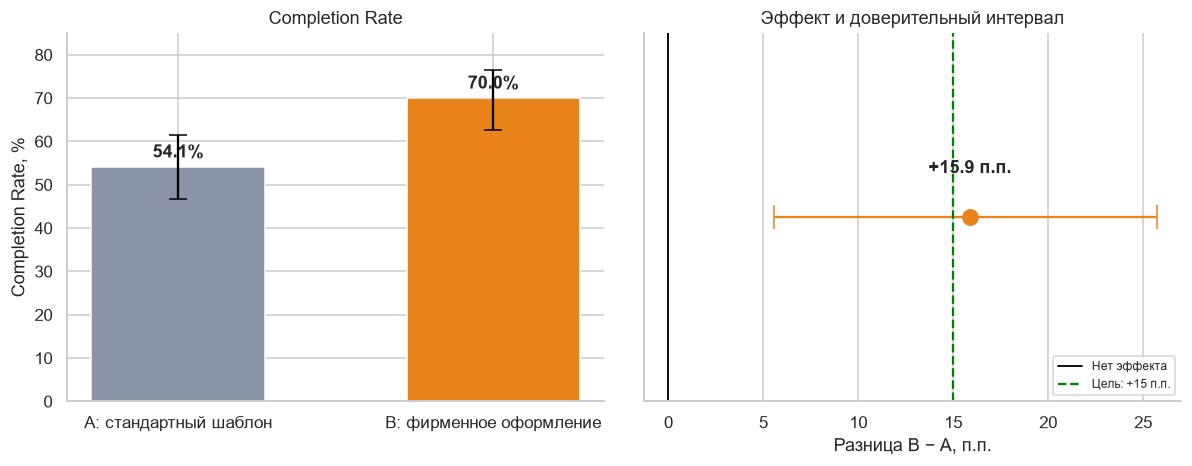

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

# (1) Completion Rate с ДИ
ax = axes[0]
for i, grp in enumerate(["A", "B"]):
    x, n = g.loc[grp]; lo_, hi_ = proportion_confint(x, n, method="wilson")
    ax.bar(i, x / n * 100, color=COLORS[grp], width=0.55)
    ax.errorbar(i, x / n * 100, yerr=[[(x / n - lo_) * 100], [(hi_ - x / n) * 100]], color="black", capsize=6)
    ax.text(i, x / n * 100 + 2.2, f"{x / n:.1%}", ha="center", fontweight="bold")
ax.set_xticks([0, 1], ["A: стандартный шаблон", "B: фирменное оформление"])
ax.set(ylabel="Completion Rate, %", ylim=(0, 85), title="Completion Rate")

# (2) разница долей и её доверительный интервал
ax = axes[1]
ax.errorbar(diff * 100, 0, xerr=[[(diff - ci_lo) * 100], [(ci_hi - diff) * 100]], fmt="o",
            color=COLORS["B"], capsize=8, ms=10)
ax.axvline(0, color="black", lw=1.2, label="Нет эффекта")
ax.axvline(MDE * 100, color="green", ls="--", lw=1.5, label=f"Цель: +{MDE * 100:.0f} п.п.")
ax.text(diff * 100, 0.12, f"{diff * 100:+.1f} п.п.", ha="center", fontweight="bold")
ax.set(xlabel="Разница B − A, п.п.", yticks=[], ylim=(-0.5, 0.5), title="Эффект и доверительный интервал")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## Раздел 5. Интерпретация и выводы

### 5.1. Статистический вывод

In [11]:
from IPython.display import Markdown

significant = p_z < ALPHA
decision = "**отвергаем H₀**" if significant else "**не отвергаем H₀**"
verdict = ("различие Completion Rate между группами статистически значимо" if significant
           else "данных недостаточно, чтобы утверждать, что кастомизация оформления влияет на Completion Rate")
display(Markdown(f'''
- **P-value (z-тест) = {p_z:.5f}** при α = {ALPHA}
- **Статистическое решение:** {decision}: {verdict}.
- Completion Rate: **{p_a:.1%} → {p_b:.1%}**, разница **{diff * 100:+.2f} п.п.** (95% ДИ: [{ci_lo * 100:+.2f}; {ci_hi * 100:+.2f}] п.п.), относительный прирост {rel_lift:+.1%}.
'''))


- **P-value (z-тест) = 0.00255** при α = 0.05
- **Статистическое решение:** **отвергаем H₀**: различие Completion Rate между группами статистически значимо.
- Completion Rate: **54.1% → 70.0%**, разница **+15.88 п.п.** (95% ДИ: [+5.57; +25.73] п.п.), относительный прирост +29.3%.


### 5.2. Бизнес-вывод

In [12]:
MONTHLY_STARTS = 20_000       # допущение: респондентов, открывающих опросы в месяц, по всей базе заказчиков
extra = diff * MONTHLY_STARTS
extra_lo, extra_hi = ci_lo * MONTHLY_STARTS, ci_hi * MONTHLY_STARTS
practical = ci_lo >= MDE      # весь ДИ выше порога значимости
practical_point = diff >= MDE

above = "выше" if practical_point else "ниже"
low_txt = ("тоже выше порога (эффект практически значим с высокой уверенностью)" if practical
           else f"ниже порога (нельзя утверждать, что эффект гарантированно достигает целевых +{MDE * 100:.0f} п.п.)")

display(Markdown(f'''
**Практическая значимость.** Порог MDE = +{MDE * 100:.0f} п.п. (+{REL_LIFT:.0%} относительно базы); фактический относительный прирост {rel_lift:+.1%}. Точечная оценка {diff * 100:+.2f} п.п. — {above} порога; нижняя граница ДИ {ci_lo * 100:+.2f} п.п. — {low_txt}.

**Что это значит для продукта (при допущении {MONTHLY_STARTS:,} стартов опросов в месяц):**
- дополнительно **≈ {extra:,.0f} завершённых анкет в месяц** (интервал {extra_lo:,.0f} … {extra_hi:,.0f});
- заказчикам нужно меньше трафика для той же выборки: чтобы собрать 1000 ответов, требуется ≈ {1000 / p_b:,.0f} вместо {1000 / p_a:,.0f} открытий опроса (на {(1 - p_a / p_b):.0%} меньше затрат на привлечение респондентов).
'''))


**Практическая значимость.** Порог MDE = +15 п.п. (+25% относительно базы); фактический относительный прирост +29.3%. Точечная оценка +15.88 п.п. — выше порога; нижняя граница ДИ +5.57 п.п. — ниже порога (нельзя утверждать, что эффект гарантированно достигает целевых +15 п.п.).

**Что это значит для продукта (при допущении 20,000 стартов опросов в месяц):**
- дополнительно **≈ 3,176 завершённых анкет в месяц** (интервал 1,114 … 5,146);
- заказчикам нужно меньше трафика для той же выборки: чтобы собрать 1000 ответов, требуется ≈ 1,429 вместо 1,848 открытий опроса (на 23% меньше затрат на привлечение респондентов).


### 5.3. Рекомендации

In [13]:
if significant and diff > 0 and practical:
    rec = "✅ **Внедрять кастомизацию оформления.** Эффект значим статистически и практически."
elif significant and diff > 0:
    rec = "🟡 **Внедрять, но осторожно** (поэтапная раскатка 10% → 50% → 100%): эффект положителен и значим, однако нижняя граница ДИ ниже целевых +15 п.п. (+25%)"
elif significant and diff < 0:
    rec = "❌ **Не внедрять:** кастомизация ухудшила Completion Rate."
else:
    rec = "⏸ **Решение не принимать на основе этого теста:** эффект не доказан; нужен больший эксперимент или пересмотр гипотезы."
display(Markdown(rec))

🟡 **Внедрять, но осторожно** (поэтапная раскатка 10% → 50% → 100%): эффект положителен и значим, однако нижняя граница ДИ ниже целевых +15 п.п. (+25%)

**Дальнейшие шаги**
1. Поэтапная раскатка (feature flag): сначала пилот на нескольких заказчиках с готовым брендом, затем 100%; быстрый откат при деградации.
2. Отделить вклад компонентов оформления (логотип / цвета / фон) следующим мультивариантным тестом — понять, какие настройки приоритетны в конструкторе.
3. Проверить **качество** ответов, а не только факт завершения: убедиться, что рост CR не сопровождается ростом «мусорных» ответов (слишком быстрое прохождение, одинаковые значения) — в СВОД есть проверка качества ответов.
4. Добавить в конструктор предупреждения о контрасте цветов (WCAG), чтобы кастомный дизайн не ухудшал читаемость.
5. Мониторинг после раскатки: эффект новизны затухает — сверить CR через 4–6 недель.

**Ограничения исследования**
- **Данные синтетические**: выводы демонстрируют *методику*; реальный эффект кастомизации необходимо подтвердить на живом трафике СВОД.
- **+25% — очень амбициозная цель** для одного визуального изменения; на практике типичные эффекты дизайна — единицы процентов. Тест с меньшим ожидаемым эффектом потребует многократно большей выборки (см. кривую мощности).
- Респондент проходит только одну форму; within-subject дизайн (каждый проходит обе формы) невозможен без искажений из-за повторения вопросов.
- Эффект зависит от **качества** фирменного оформления заказчика: «плохой» кастомный дизайн может конверсию снизить. Тест оценивает усреднённое аккуратно сделанное оформление.
- Механизм гипотезы («респонденты стали лояльнее») напрямую не проверялся: тест фиксирует только рост конверсии.
- Бизнес-оценка (20 000 стартов/мес) — допущение, а не измерение.
- Возможна недельная сезонность; тест должен охватывать целое число недель.
- Единица рандомизации — cookie: один человек с двух устройств может попасть в обе группы (смещает эффект к нулю).